# Polynomial Logistic Regression

Standard Logistic Regression draws a **linear** decision boundary. When two classes are not linearly separable — such as a U-shaped distribution — a linear boundary cannot achieve good accuracy no matter how the weights are tuned.

**Polynomial Logistic Regression** fixes this by first transforming the input features into polynomial combinations, then training a logistic classifier in that expanded space. In the original input space this produces a **curved** boundary.

$$
[X, Y]
\xrightarrow{\text{PolynomialFeatures}(d)}
[X,\; Y,\; X^2,\; XY,\; Y^2,\; \ldots]
\xrightarrow{\text{LogisticRegression}}
\hat{y}
$$

The key insight: **the model is still linear in the transformed features** — only the input space is non-linear.

## Learning Objectives

By the end of this notebook, you will be able to:

- recognize when a linear decision boundary is insufficient;
- apply `PolynomialFeatures` to generate non-linear features for a linear classifier;
- understand how polynomial degree controls the complexity of the decision boundary; and
- diagnose underfitting and overfitting from boundary plots and cross-validated accuracy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

sns.set_theme(style="whitegrid")

## 1. Load and Explore the Dataset

The dataset (`ushape.csv`) contains a synthetic 2D binary classification problem.

| Column | Description |
|---|---|
| `X` | First input feature |
| `Y` | Second input feature |
| `class` | Binary label — `0.0` or `1.0` |

The scatter plot below reveals the **U-shaped** class boundary that motivates this notebook.

In [2]:
df = pd.read_csv('dataset/ushape.csv')

In [3]:
df.head()

,X,Y,class
0,0.0316,0.9870,0.0
1,2.1200,-0.0462,1.0
2,0.8820,-0.0758,0.0
3,-0.0551,-0.0373,1.0
4,0.8300,-0.5390,1.0


In [4]:
print("=== Data types and null check ===")
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print("\n=== Summary statistics ===")
df.describe()

=== Data types and null check ===
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       100 non-null    float64
 1   Y       100 non-null    float64
 2   class   100 non-null    float64
dtypes: float64(3)
memory usage: 2.5 KB

Missing values per column:
X        0
Y        0
class    0
dtype: int64

Duplicate rows: 0

=== Summary statistics ===


,X,Y,class
count,100.000000,100.000000,100.000000
mean,0.500579,0.228688,0.500000
std,0.891263,0.593023,0.502519
min,-1.320000,-1.040000,0.000000
25%,-0.140500,-0.203250,0.000000
50%,0.470500,0.188500,0.500000
75%,1.107500,0.658250,1.000000
max,2.180000,1.570000,1.000000


In [5]:
X = df[["X", "Y"]].values
y = df["class"].values

print("Dataset shape:", X.shape)
print("Class distribution:", dict(zip(*np.unique(y, return_counts=True))))

Dataset shape: (100, 2)
Class distribution: {np.float64(0.0): np.int64(50), np.float64(1.0): np.int64(50)}


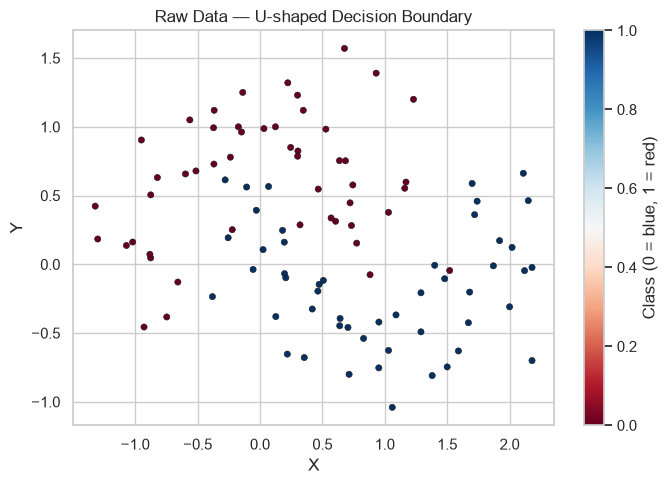

In [6]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu", edgecolors="k", linewidths=0.4, s=20)
plt.colorbar(scatter, label="Class (0 = blue, 1 = red)")
plt.title("Raw Data — U-shaped Decision Boundary")
plt.xlabel("X")
plt.ylabel("Y")
plt.tight_layout()
plt.show()

### Observation: A Linear Boundary Cannot Separate These Classes

- Class 0 (blue) wraps *inside* the U-curve.
- Class 1 (red) fills *outside* the curve.
- A logistic regression with raw features $X$ and $Y$ draws a straight line as its decision boundary.

No values of $w_1$, $w_2$, $b$ can make a single line correctly separate the two classes here.

## 2. Baseline — Linear Logistic Regression

### The Logistic Function

Binary logistic regression predicts the **probability** that a sample belongs to class 1:

$$P(y=1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z = w_1 X + w_2 Y + b$$

$\sigma(z)$ (the **sigmoid function**) maps any real logit $z$ into the interval $(0, 1)$:

| $z$ | $\sigma(z)$ | Interpretation |
|---|---|---|
| $-\infty$ | 0.00 | Certain class 0 |
| $-2$ | 0.12 | Likely class 0 |
| $0$ | **0.50** | Decision threshold |
| $+2$ | 0.88 | Likely class 1 |
| $+\infty$ | 1.00 | Certain class 1 |

The **decision boundary** is the line where $P = 0.5$, i.e. $z = 0$:

$$w_1 X + w_2 Y + b = 0$$

### Loss: Binary Cross-Entropy

Training minimises the **binary cross-entropy** over all $N$ samples:

$$\mathcal{L}(w, b) = -\frac{1}{N} \sum_{i=1}^{N} \Bigl[ y_i \log \hat{p}_i + (1 - y_i) \log(1 - \hat{p}_i) \Bigr]$$

where $\hat{p}_i = \sigma(z_i)$ is the predicted probability for sample $i$. By default, scikit-learn also adds an L2 regularisation penalty $\frac{1}{2C}\|\mathbf{w}\|^2$ to this objective.

In [7]:
cv_fold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

clf = LogisticRegression(max_iter=1000)
clf.fit(X, y)

print(f"Learned weights:   w1 (X) = {clf.coef_[0][0]:.4f},  w2 (Y) = {clf.coef_[0][1]:.4f}")
print(f"Learned intercept: b      = {clf.intercept_[0]:.4f}")
print(f"\nDecision boundary line: {clf.coef_[0][0]:.4f}·X + {clf.coef_[0][1]:.4f}·Y + {clf.intercept_[0]:.4f} = 0")

Learned weights:   w1 (X) = 1.1820,  w2 (Y) = -2.4748
Learned intercept: b      = 0.0102

Decision boundary line: 1.1820·X + -2.4748·Y + 0.0102 = 0


In [8]:
baseline_accuracy = np.mean(cross_val_score(clf, X, y, scoring="accuracy", cv=cv_fold))
print(f"Baseline linear accuracy (10-fold stratified CV): {baseline_accuracy:.4f}")

Baseline linear accuracy (10-fold stratified CV): 0.8300


### Baseline Result

The cross-validated accuracy above (≈ 83%) confirms the linear boundary misses a significant portion of the U-shaped class. We need a curved boundary.

> **Note on fold size:** With 100 samples and 10 folds, each evaluation fold contains only 10 samples — so accuracy estimates have higher variance than on larger datasets. Treat the exact values as indicative rather than precise.

## 3. Polynomial Feature Expansion

`PolynomialFeatures` generates all polynomial and interaction combinations of the inputs up to a given degree. For two inputs $X$ and $Y$:

| Degree | Features added | Total features |
|---|---|---|
| 1 (original) | — | 2 |
| 2 | $X^2,\; XY,\; Y^2$ | 5 |
| 3 | $X^3,\; X^2Y,\; XY^2,\; Y^3$ | 9 |
| $d$ | all degree-$d$ combos | $\displaystyle\binom{2+d}{d} - 1$ |

After transformation, logistic regression fits a **linear** decision surface in the expanded space — which is a **polynomial curve** in the original $(X, Y)$ space.

**Key parameters:**
- `degree` — maximum polynomial degree; higher = more complex curve, higher risk of overfitting.
- `include_bias=False` — skip the constant column (logistic regression adds its own intercept).

> ⚠️ **Note on data leakage (sections 3 & 4):** The code below calls `poly.fit_transform(X)` on the *full* dataset before passing the result to `cross_val_score`. This technically leaks polynomial statistics from the held-out test fold into training, giving a slightly optimistic accuracy estimate. On this simple 100-sample dataset the effect is negligible — the pattern is kept here for clarity. **Section 5 shows the correct approach** using `make_pipeline`, which fits the transformer only on the training fold inside each CV split.

In [9]:
poly = PolynomialFeatures(degree=3, include_bias=False)
X_trf = poly.fit_transform(X)

print("Original feature count:", X.shape[1])
print("Expanded feature count (degree 3):", X_trf.shape[1])
print("Feature names:", poly.get_feature_names_out(["X", "Y"]))

Original feature count: 2
Expanded feature count (degree 3): 9
Feature names: ['X' 'Y' 'X^2' 'X Y' 'Y^2' 'X^3' 'X^2 Y' 'X Y^2' 'Y^3']


### Feature Expansion Output

At degree 3, the 2 original inputs $(X, Y)$ expand to **9 features**:

$$X,\; Y,\; X^2,\; XY,\; Y^2,\; X^3,\; X^2Y,\; XY^2,\; Y^3$$

This matches the formula: $\displaystyle\binom{2+3}{3} - 1 = \binom{5}{3} - 1 = 10 - 1 = 9$

Each new feature is a non-linear combination of the originals. Adding them as inputs lets a linear logistic classifier draw a **cubic curve** as its decision boundary in the original $(X, Y)$ plane.

In [10]:
poly_clf = LogisticRegression(max_iter=1000)
poly_accuracy = np.mean(cross_val_score(poly_clf, X_trf, y, scoring="accuracy", cv=cv_fold))
print(f"Polynomial (degree 3) accuracy (10-fold stratified CV): {poly_accuracy:.4f}")
print(f"Improvement over baseline: +{poly_accuracy - baseline_accuracy:.4f}")

Polynomial (degree 3) accuracy (10-fold stratified CV): 0.9100
Improvement over baseline: +0.0800


### Polynomial Result

With degree 3, the cross-validated accuracy jumps significantly — the curved boundary captures the U-shape.

## 4. Decision Boundaries Across Polynomial Degrees

The `plot_decision_boundary` function below fits `PolynomialFeatures(degree=d)` + `LogisticRegression`, evaluates accuracy with 10-fold CV, and draws the resulting boundary. The shaded regions show the predicted class for every point in the 2D plane.

**What to look for as degree increases:**

| Degree | Expected behaviour |
|---|---|
| 1 | Straight line — underfits the U-shape |
| 2–3 | Curved boundary begins capturing the shape |
| 4–5 | Boundary fits the training data well; accuracy near-peak |
| 6–7 | Boundary contorts slightly, overfitting noise |
| 25 | Severe overfitting — extreme wiggles around individual points |

In [11]:
def plot_decision_boundary(X, y, degree=1, ax=None):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_trf = poly.fit_transform(X)

    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_trf, y)

    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    accuracy = np.mean(cross_val_score(clf, X_trf, y, scoring="accuracy", cv=cv))

    a = np.arange(start=X[:, 0].min() - 1, stop=X[:, 0].max() + 1, step=0.01)
    b = np.arange(start=X[:, 1].min() - 1, stop=X[:, 1].max() + 1, step=0.01)
    XX, YY = np.meshgrid(a, b)

    grid = np.c_[XX.ravel(), YY.ravel()]
    labels = clf.predict(poly.transform(grid))

    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))

    ax.contourf(XX, YY, labels.reshape(XX.shape), alpha=0.4, cmap="RdBu")
    ax.scatter(
        X[:, 0], X[:, 1],
        c=y, edgecolors="k", linewidths=0.4, cmap="RdBu", zorder=2, s=20,
    )
    ax.set_title(f"Degree = {degree}  |  CV acc = {accuracy:.4f}", fontsize=10)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    return ax

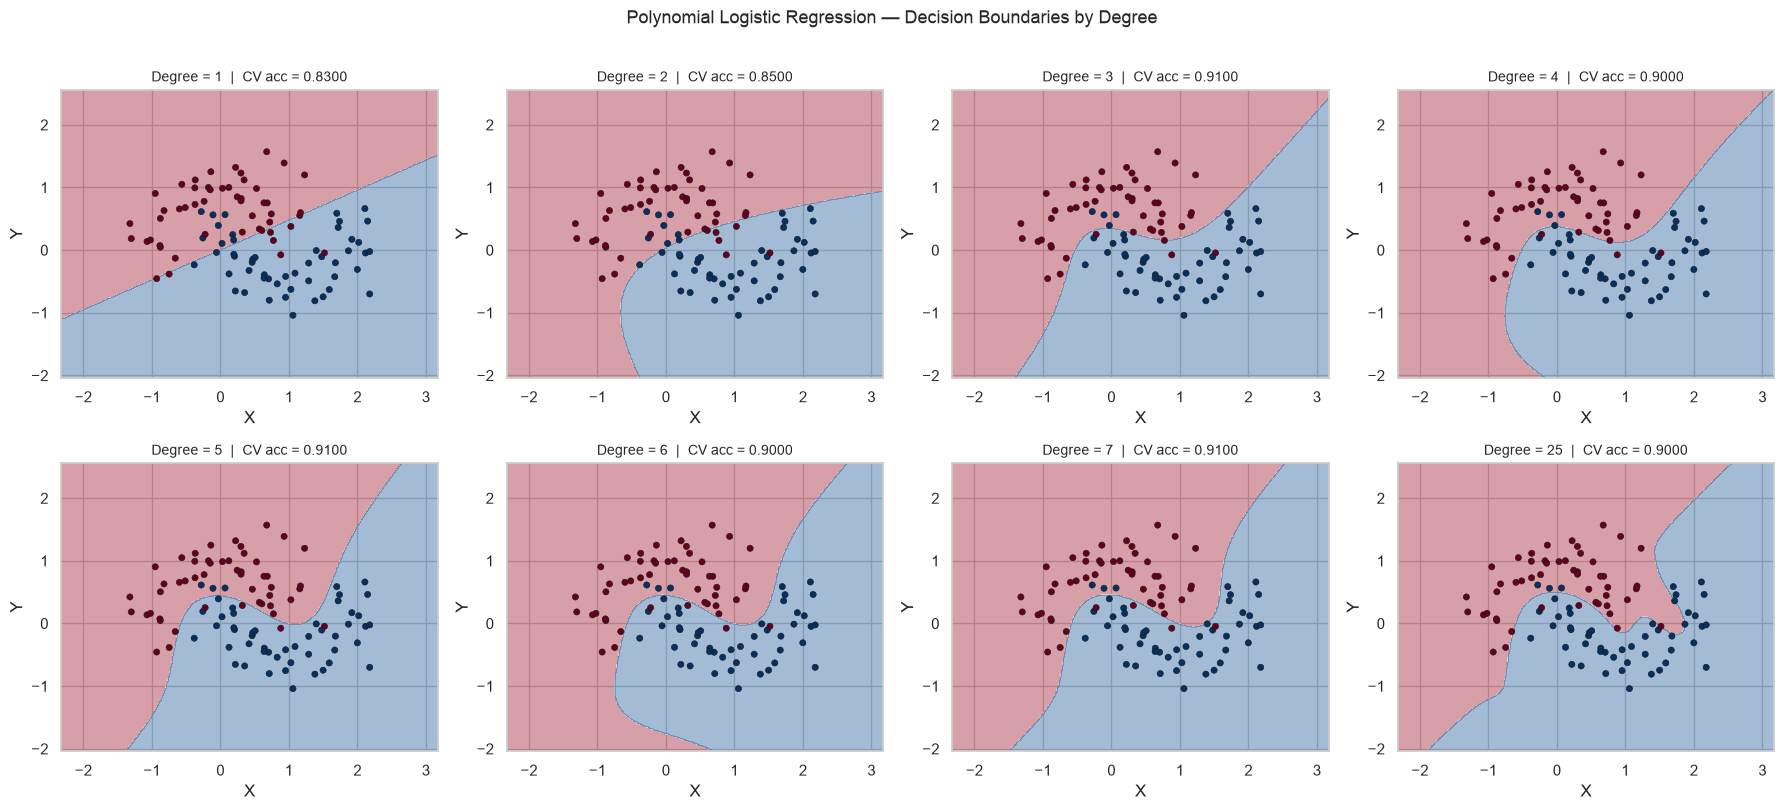

In [12]:
degrees = [1, 2, 3, 4, 5, 6, 7, 25]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, degree in zip(axes.ravel(), degrees):
    plot_decision_boundary(X, y, degree=degree, ax=ax)

plt.suptitle(
    "Polynomial Logistic Regression — Decision Boundaries by Degree",
    fontsize=13, y=1.01,
)
plt.tight_layout()
plt.show()

## 5. Degree Selection and Production Pipeline

### Systematically Finding the Best Degree

Rather than choosing a degree by eye from the boundary plots, the table below computes 10-fold CV accuracy for every degree from 1 to 10. The best-performing degree is then used to build a production-ready pipeline.

### Why Use `make_pipeline`?

Calling `PolynomialFeatures.fit_transform(X)` on the full dataset before cross-validation **leaks** polynomial statistics from the test fold into training. `make_pipeline` prevents this — it fits the transformer **only on the training fold** inside each CV split and then transforms the test fold separately. This is the correct way to include preprocessing in a cross-validated workflow and to deploy the model later.

In [13]:
rows = []
for d in range(1, 11):
    poly_d = PolynomialFeatures(degree=d, include_bias=False)
    X_d = poly_d.fit_transform(X)
    clf_d = LogisticRegression(max_iter=1000)
    acc = np.mean(cross_val_score(clf_d, X_d, y, scoring="accuracy", cv=cv_fold))
    rows.append({"degree": d, "feature_count": X_d.shape[1], "cv_accuracy": acc})

degree_df = pd.DataFrame(rows).set_index("degree")
best_degree = int(degree_df["cv_accuracy"].idxmax())
print(f"Best degree: {best_degree}  (CV accuracy = {degree_df.loc[best_degree, 'cv_accuracy']:.4f})")
display(degree_df.round(4))

Best degree: 3  (CV accuracy = 0.9100)


,feature_count,cv_accuracy
degree,,
1,2,0.83
2,5,0.85
3,9,0.91
4,14,0.90
5,20,0.91
6,27,0.90
7,35,0.91
8,44,0.91
9,54,0.91


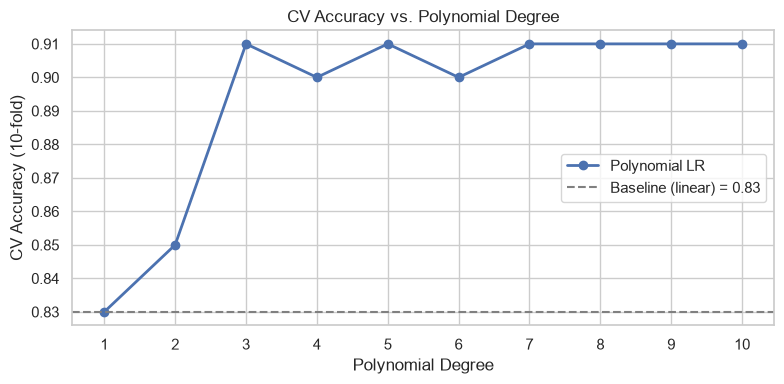

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(degree_df.index, degree_df["cv_accuracy"], marker="o", linewidth=2, label="Polynomial LR")
ax.axhline(baseline_accuracy, linestyle="--", color="gray", label=f"Baseline (linear) = {baseline_accuracy:.2f}")
ax.set_xlabel("Polynomial Degree")
ax.set_ylabel("CV Accuracy (10-fold)")
ax.set_title("CV Accuracy vs. Polynomial Degree")
ax.set_xticks(degree_df.index)
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation

- Accuracy **jumps from 0.83 → 0.91** at degree 3 — the first degree that produces a boundary curved enough to wrap around the U-shape.
- Beyond degree 3, accuracy **plateaus at 0.91** regardless of how many features are added. More complexity gives zero benefit on this dataset.
- Feature count grows from 9 (degree 3) to 65 (degree 10) — a **7× increase for the same accuracy**.
- **Degree 3 is the elbow point**: the best trade-off between model complexity and performance. The chart above makes this easy to see at a glance.

In [15]:
best_pipeline = make_pipeline(
    PolynomialFeatures(degree=best_degree, include_bias=False),
    LogisticRegression(max_iter=1000),
)

pipeline_accuracy = np.mean(cross_val_score(best_pipeline, X, y, scoring="accuracy", cv=cv_fold))
print(f"Pipeline (degree={best_degree}) CV accuracy: {pipeline_accuracy:.4f}")
print()
print("Pipeline steps:")
for step_name, step_obj in best_pipeline.steps:
    print(f"  {step_name}: {step_obj}")

Pipeline (degree=3) CV accuracy: 0.9100

Pipeline steps:
  polynomialfeatures: PolynomialFeatures(degree=3, include_bias=False)
  logisticregression: LogisticRegression(max_iter=1000)


### Section 5 Summary

The `make_pipeline` result (0.91) matches the earlier hand-crafted score — but is now **leakage-free** and ready for deployment:

- **During training:** `.fit(X_train, y_train)` fits the polynomial transformer and classifier together, ensuring the transformer learns only from training data.
- **During inference:** `.predict(X_new)` applies the correct transformation automatically — no manual `poly.transform()` needed.
- **Correct cross-validation:** `cross_val_score(pipeline, X, y, ...)` refits the *entire* pipeline (transformer + classifier) inside every fold.

On this simple synthetic dataset the leaky and pipeline scores happen to be identical (0.91). On real-world data with high-degree features or a small dataset, the leaky approach would give an inflated estimate while the pipeline gives the honest out-of-sample accuracy.

## Key Takeaways

- **Linear logistic regression fails on U-shaped data** — no straight line can separate the classes regardless of weights.
- **Polynomial feature expansion** adds new columns ($X^2$, $XY$, $Y^2$, …) so that a linear classifier produces a curved boundary in the original space.
- The model is still **linear in the transformed features** — only the representation of the input changes, not the algorithm.
- **Degree is the key hyperparameter**: too low → underfitting; too high → overfitting. Cross-validation finds the sweet spot; the accuracy-vs-degree plot makes the elbow point visible.
- **Feature count grows rapidly** with degree: $\binom{p+d}{d}-1$ for $p$ inputs. At degree 25 with 2 inputs there are $\binom{27}{2}-1 = 350$ features — far more than most training sets can support.
- **Regularisation becomes critical at high degrees.** `LogisticRegression` defaults to `C=1.0` (moderate L2 penalty). When the feature count far exceeds the sample count (e.g. degree ≥ 8 here), tuning `C` via grid search prevents the model from fitting noise.
- In practice, use a scikit-learn **`Pipeline`** (`PolynomialFeatures` → `LogisticRegression`) to ensure the transformer is fit only on training data in each CV fold and to avoid data leakage.